# Task 6: Diamond prices (reference solution)

This is the finished version of every worked example in `03_ml/notes/task6_ex*.md`, with its real outputs. **Type your own version first** in `03_ml/diamond_prices.ipynb`, then use this file to compare or to get unstuck.

It runs from `03_ml/examples/`, so the paths start with `../` (the notes, written for `03_ml/`, don't have that). Its charts and model files go to the same `03_ml/output/` and `03_ml/models/` folders as yours, and they come out identical.

In [1]:
import pickle
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)

## Exercise 1: Load, look at the price, split, baseline

In [2]:
df = pd.read_csv("../data/diamonds.csv")
print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("Rows with a size of 0 mm:", (df[["x", "y", "z"]] == 0).any(axis=1).sum())
display(df.head())

(53940, 10)
Missing values: 0
Rows with a size of 0 mm: 20


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
price = df["price"]
print(f"Cheapest: ${price.min():,}   Median: ${price.median():,.0f}   "
      f"Mean: ${price.mean():,.0f}   Most expensive: ${price.max():,}")
print(f"Diamonds under $2,500: {(price < 2500).mean():.0%}")

Cheapest: $326   Median: $2,401   Mean: $3,933   Most expensive: $18,823
Diamonds under $2,500: 51%


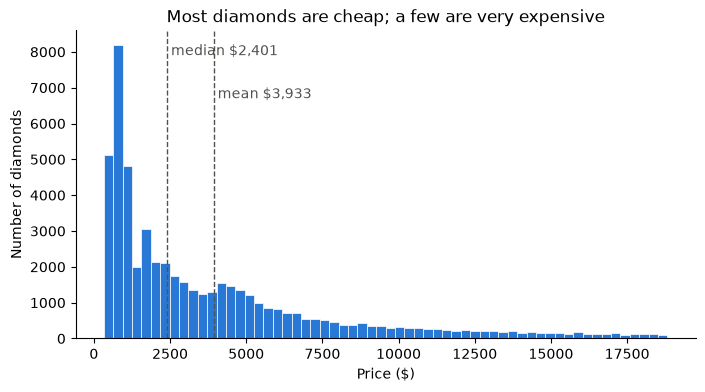

In [4]:
output_dir = Path("../output")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(price, bins=60, color="#2a78d6", edgecolor="white", linewidth=0.5)
top = ax.get_ylim()[1]
for value, label, height in [(price.median(), "median", 0.92),
                             (price.mean(), "mean", 0.78)]:
    ax.axvline(value, color="#52514e", linewidth=1, linestyle="--")
    ax.text(value, top * height, f" {label} ${value:,.0f}", color="#52514e")
ax.set(title="Most diamonds are cheap; a few are very expensive",
       xlabel="Price ($)", ylabel="Number of diamonds")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(output_dir / "price_histogram.png", bbox_inches="tight")
plt.show()

In [5]:
features = ["carat", "cut", "color", "clarity", "depth", "table"]
X = df[features]
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Mean price - train: ${y_train.mean():,.0f}, test: ${y_test.mean():,.0f}")

Train: (43152, 6)  Test: (10788, 6)
Mean price - train: $3,939, test: $3,906


In [6]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
print("Baseline predicts:", baseline.predict(X_test.head(3)))
baseline_mae = mean_absolute_error(y_test, baseline.predict(X_test))
print(f"Baseline MAE: ${baseline_mae:,.0f}")

Baseline predicts: [3939.49070727 3939.49070727 3939.49070727]
Baseline MAE: $3,021


## Exercise 1 answers
- **Data:** 53,940 diamonds, 10 columns, 0 missing values. 20 rows have a size of 0 mm, which is impossible (data-entry errors).
- **Price:** $326 to $18,823. The median ($2,401) is far below the mean ($3,933): most diamonds are cheap and a few expensive ones pull the mean up (right-skewed). 51% cost under $2,500.
- **X** = `carat`, `cut`, `color`, `clarity`, `depth`, `table`; **y** = `price`. **Left out:** `x`, `y`, `z` are the size in mm, which `carat` (the weight) already measures, and they contain the 20 impossible zeros.
- **No `stratify`:** price is a number with 11,602 different values, so there are no categories to balance. With 54k rows a random split is already balanced ($3,939 vs $3,906 mean).
- **Baseline:** always predicts the mean, $3,939. **MAE $3,021**. Every real model must beat this.

## Exercise 2: A straight line (carat only)

In [7]:
line = LinearRegression()
line.fit(X_train[["carat"]], y_train)
print(f"price = {line.intercept_:,.0f} + {line.coef_[0]:,.0f} × carat")

price = -2,262 + 7,769 × carat


In [8]:
sizes = pd.DataFrame({"carat": [0.2, 0.3, 0.5, 1.0, 2.0]})
display(sizes.assign(predicted_price=line.predict(sizes).round(0)))

,carat,predicted_price
0,0.2,-708.0
1,0.3,69.0
2,0.5,1623.0
3,1.0,5507.0
4,2.0,13276.0


In [9]:
def evaluate(name, predictions):
    """Print the 3 regression scores for one model on the test set."""
    mae = mean_absolute_error(y_test, predictions)
    rmse = root_mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    print(f"{name:<24} MAE ${mae:>6,.0f}   RMSE ${rmse:>6,.0f}   R² {r2:.3f}")


line_pred = line.predict(X_test[["carat"]])
evaluate("baseline (mean)", baseline.predict(X_test))
evaluate("line (carat only)", line_pred)
print("Negative prices predicted:", (line_pred < 0).sum())

baseline (mean)          MAE $ 3,021   RMSE $ 3,987   R² -0.000
line (carat only)        MAE $ 1,010   RMSE $ 1,550   R² 0.849
Negative prices predicted: 339


## Exercise 2 answers
- **Line:** price = −2,262 + 7,769 × carat. Each carat adds $7,769; the intercept only places the line.
- **Predictions:** 0.2 carat → **−$708** (a negative price), 1 carat → $5,507, 2 carats → $13,276.
- **Scores:** MAE **$1,010**, RMSE $1,550, R² **0.849** vs the baseline's $3,021, $3,987 and 0. Weight alone explains 85% of the price differences.
- **Problem:** 339 test diamonds get a negative price. A straight line doesn't know that prices can't go below 0.

## Exercise 3: Look at the errors

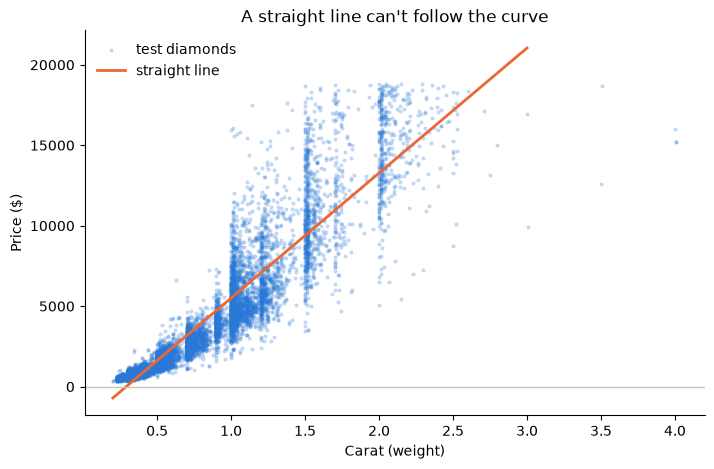

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_test["carat"], y_test, s=4, alpha=0.2, color="#2a78d6",
           label="test diamonds")
ends = pd.DataFrame({"carat": [0.2, 3.0]})
ax.plot(ends["carat"], line.predict(ends), color="#eb6834", linewidth=2,
        label="straight line")
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set(title="A straight line can't follow the curve",
       xlabel="Carat (weight)", ylabel="Price ($)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(output_dir / "carat_line.png", bbox_inches="tight")
plt.show()

In [11]:
errors = y_test - line_pred
bands = pd.cut(X_test["carat"], [0, 0.5, 1, 1.5, 2, 5.5])
display(errors.groupby(bands, observed=True).agg(["count", "mean"]).round(0))

,count,mean
carat,,
"(0.0, 0.5]",3834,353.0
"(0.5, 1.0]",3478,-548.0
"(1.0, 1.5]",2370,-216.0
"(1.5, 2.0]",727,884.0
"(2.0, 5.5]",379,489.0


## Exercise 3 answers
- **Chart:** prices curve upwards with carat, but the line is straight. It's too low for small diamonds (even below $0), too high around 0.5–1 carat and too low again around 1.5–2 carats.
- **Mean error by size:** +$353 (0–0.5 carat), −$548 (0.5–1), −$216 (1–1.5), **+$884** (1.5–2), +$489 (over 2).
- **Lesson:** errors with a pattern mean the model has the wrong shape. Also visible: stripes at 1.0, 1.5 and 2.0 carats ("magic" weights) and no prices above $18,823.

## Exercise 4: All features, and the cut puzzle

In [12]:
display(df.groupby("cut")[["price", "carat"]].mean().round(2).sort_values("price"))

,price,carat
cut,,
Ideal,3457.54,0.70
Good,3928.86,0.85
Very Good,3981.76,0.81
Fair,4358.76,1.05
Premium,4584.26,0.89


In [13]:
numeric = ["carat", "depth", "table"]
categorical = ["cut", "color", "clarity"]
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])
linear = Pipeline([("prep", preprocess), ("model", LinearRegression())])
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)
evaluate("linear (all features)", linear_pred)
print("Negative prices predicted:", (linear_pred < 0).sum())

linear (all features)    MAE $   802   RMSE $ 1,160   R² 0.915
Negative prices predicted: 1034


In [14]:
coefs = pd.Series(linear["model"].coef_,
                  index=linear["prep"].get_feature_names_out())
for group in categorical:
    print(coefs.filter(like=f"{group}_").sort_values().round(0), "\n")

cat__cut_Fair        -631.0
cat__cut_Good          -4.0
cat__cut_Very Good    170.0
cat__cut_Premium      194.0
cat__cut_Ideal        271.0
dtype: float64 

cat__color_J   -1495.0
cat__color_I    -620.0
cat__color_H    -162.0
cat__color_G     311.0
cat__color_F     522.0
cat__color_E     613.0
cat__color_D     831.0
dtype: float64 

cat__clarity_I1     -3800.0
cat__clarity_SI2    -1178.0
cat__clarity_SI1     -219.0
cat__clarity_VS2      407.0
cat__clarity_VS1      727.0
cat__clarity_VVS2    1166.0
cat__clarity_VVS1    1271.0
cat__clarity_IF      1626.0
dtype: float64 



## Exercise 4 answers
- **Puzzle:** Ideal (the best cut) is the cheapest on average ($3,458), because Ideal diamonds are small (0.70 carat vs 1.05 for Fair). Size is a **confounder**, so the simple average compares sizes, not cuts.
- **All 6 features** (scaled numbers + one-hot grades → linear regression): MAE **$802**, RMSE $1,160, R² **0.915**, better than carat alone ($1,010).
- **Solved:** at the same size, Ideal is worth **$902 more** than Fair; D beats J by $2,326 and IF beats I1 by $5,426. Compare weights only within a group.
- **Still wrong:** 1,034 negative prices, because the grade weights are fixed dollar amounts, not percentages.

## Exercise 5: Log scales

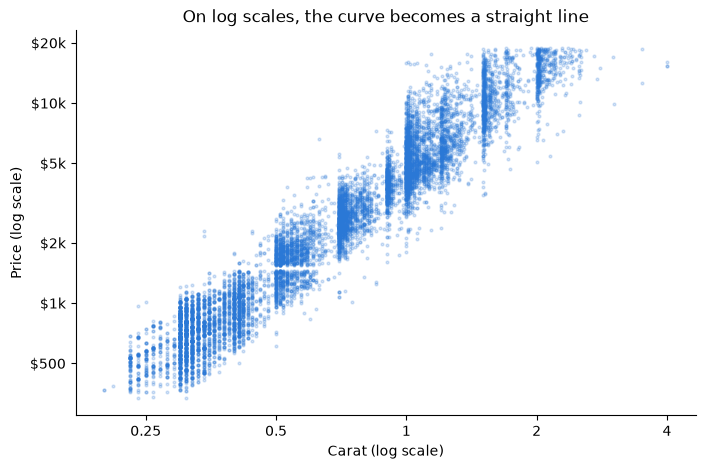

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_test["carat"], y_test, s=4, alpha=0.2, color="#2a78d6")
ax.set(xscale="log", yscale="log",
       title="On log scales, the curve becomes a straight line",
       xlabel="Carat (log scale)", ylabel="Price (log scale)")
ax.set_xticks([0.25, 0.5, 1, 2, 4], labels=["0.25", "0.5", "1", "2", "4"])
ax.set_yticks([500, 1000, 2000, 5000, 10000, 20000],
              labels=["$500", "$1k", "$2k", "$5k", "$10k", "$20k"])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(output_dir / "log_scales.png", bbox_inches="tight")
plt.show()

In [16]:
log_preprocess = ColumnTransformer([
    ("log", FunctionTransformer(np.log, feature_names_out="one-to-one"), ["carat"]),
    ("num", StandardScaler(), ["depth", "table"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])
log_linear = TransformedTargetRegressor(
    regressor=Pipeline([("prep", log_preprocess), ("model", LinearRegression())]),
    func=np.log,
    inverse_func=np.exp,
)
log_linear.fit(X_train, y_train)
log_pred = log_linear.predict(X_test)
evaluate("linear on log scales", log_pred)
print("Negative prices predicted:", (log_pred < 0).sum())

linear on log scales     MAE $   400   RMSE $   820   R² 0.958
Negative prices predicted: 0


In [17]:
inner = log_linear.regressor_
log_coefs = pd.Series(inner["model"].coef_,
                      index=inner["prep"].get_feature_names_out())
k = log_coefs["log__carat"]
print(f"carat: 1% heavier → {k:.2f}% pricier; twice as heavy → {2 ** k:.1f}× the price")
for better, worse in [("cut_Ideal", "cut_Fair"),
                      ("color_D", "color_J"),
                      ("clarity_IF", "clarity_I1")]:
    ratio = np.exp(log_coefs[f"cat__{better}"] - log_coefs[f"cat__{worse}"])
    print(f"{better} vs {worse}: {ratio:.2f}× the price")

carat: 1% heavier → 1.89% pricier; twice as heavy → 3.7× the price
cut_Ideal vs cut_Fair: 1.18× the price
color_D vs color_J: 1.67× the price
clarity_IF vs clarity_I1: 3.07× the price


In [18]:
half_log = TransformedTargetRegressor(
    regressor=Pipeline([("prep", clone(preprocess)), ("model", LinearRegression())]),
    func=np.log,
    inverse_func=np.exp,
)
half_log.fit(X_train, y_train)
half_pred = half_log.predict(X_test)
evaluate("log price only", half_pred)
biggest = half_pred.argmax()
print(f"Biggest prediction: ${half_pred[biggest]:,.0f} for a "
      f"{X_test['carat'].iloc[biggest]} carat diamond "
      f"(real price ${y_test.iloc[biggest]:,})")

log price only           MAE $ 1,859   RMSE $17,816   R² -18.968
Biggest prediction: $1,005,632 for a 4.01 carat diamond (real price $15,223)


## Exercise 5 answers
- **Chart:** on log–log axes the curved cloud becomes a straight band, so "+1% carat" always means about the same % more price.
- **Linear on log scales** (`FunctionTransformer(np.log)` on carat + `TransformedTargetRegressor` on price): MAE **$400** (half of $802), RMSE $820, R² **0.958**, **0** negative prices (`exp` is always positive).
- **Weights as ratios:** twice the carat = **3.7×** the price; at the same size Ideal = 1.18× Fair, D = 1.67× J, IF = 3.07× I1. Grades multiply the price; they don't add a fixed amount.
- **Trap:** logging only the price makes price exponential in carat: R² **−18.97**, and a 4.01 carat diamond is predicted at $1,005,632 (real $15,223). Check the shape with a chart and look at RMSE, not only MAE.

## Exercise 6: Trees and gradient boosting

In [19]:
grades = [
    ["Fair", "Good", "Very Good", "Premium", "Ideal"],        # cut, worst → best
    ["J", "I", "H", "G", "F", "E", "D"],                       # color
    ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"],  # clarity
]
tree_preprocess = ColumnTransformer([
    ("num", "passthrough", numeric),
    ("cat", OrdinalEncoder(categories=grades), categorical),
])
sample = X_train.head(3)
display(sample)
display(pd.DataFrame(tree_preprocess.fit(X_train).transform(sample),
                     columns=tree_preprocess.get_feature_names_out(),
                     index=sample.index))

,carat,cut,color,clarity,depth,table
26546,2.01,Good,F,SI2,58.1,64.0
9159,1.01,Very Good,E,SI2,60.0,60.0
14131,1.10,Premium,H,VS2,62.5,58.0


,num__carat,num__depth,num__table,cat__cut,cat__color,cat__clarity
26546,2.01,58.1,64.0,1.0,4.0,1.0
9159,1.01,60.0,60.0,2.0,5.0,1.0
14131,1.10,62.5,58.0,3.0,2.0,3.0


In [20]:
def tree_model(estimator):
    """The ordered-grades cleaning step, followed by any tree model."""
    return Pipeline([("prep", clone(tree_preprocess)), ("model", estimator)])


trees = {
    "random forest": tree_model(RandomForestRegressor(random_state=42, n_jobs=-1)),
    "gradient boosting": tree_model(HistGradientBoostingRegressor(random_state=42)),
}
for name, model in trees.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    seconds = time.perf_counter() - start
    train_mae = mean_absolute_error(y_train, model.predict(X_train))
    print(f"{name}: trained in {seconds:.1f} s, train MAE ${train_mae:,.0f}")
    evaluate(name, model.predict(X_test))

random forest: trained in 1.2 s, train MAE $111
random forest            MAE $   280   RMSE $   554   R² 0.981


gradient boosting: trained in 0.6 s, train MAE $272
gradient boosting        MAE $   286   RMSE $   553   R² 0.981


In [21]:
forest = trees["random forest"]
importance = pd.Series(forest["model"].feature_importances_,
                       index=forest["prep"].get_feature_names_out())
print(importance.sort_values(ascending=False).round(3))

num__carat      0.885
cat__clarity    0.067
cat__color      0.033
num__depth      0.008
num__table      0.004
cat__cut        0.003
dtype: float64


In [22]:
for name, model in trees.items():
    print(f"{name}: {len(pickle.dumps(model)) / 1e6:,.1f} MB")

random forest: 338.6 MB
gradient boosting: 0.4 MB


## Exercise 6 answers
- **Ordered grades:** `OrdinalEncoder(categories=...)` turns each grade into its position, worst = 0 (Good → 1, Very Good → 2, Premium → 3). Trees don't need scaling or one-hot, and 3 columns train much faster than 20.
- **Random forest:** train MAE $111, test MAE **$280**, R² 0.981 (about 1 s). **Gradient boosting:** train $272, test **$286**, R² 0.981 (about 0.2 s). Both beat the log-scale line ($400).
- **Importances:** carat **0.885**, clarity 0.067, colour 0.033; cut, depth and table almost nothing.
- **File size:** forest **338.6 MB** vs boosting 0.4 MB. Same accuracy, so boosting is the one to use (and the forest is too big for GitHub).

## Exercise 7: Cross-validation and tuning

In [23]:
candidates = {
    "linear (all features)": clone(linear),
    "linear on log scales": clone(log_linear),
    "random forest": tree_model(RandomForestRegressor(random_state=42, n_jobs=-1)),
    "gradient boosting": tree_model(HistGradientBoostingRegressor(random_state=42)),
}
for name, model in candidates.items():
    scores = -cross_val_score(
        model, X_train, y_train, cv=5, scoring="neg_mean_absolute_error"
    )
    print(f"{name:<24} MAE ${scores.mean():,.0f} ± {scores.std():,.0f}")

linear (all features)    MAE $806 ± 7


linear on log scales     MAE $404 ± 4


random forest            MAE $287 ± 5


gradient boosting        MAE $286 ± 6


In [24]:
grid = GridSearchCV(
    tree_model(HistGradientBoostingRegressor(random_state=42)),
    param_grid={
        "model__learning_rate": [0.05, 0.1, 0.2],
        "model__max_leaf_nodes": [15, 31, 63],
    },
    cv=5,
    scoring="neg_mean_absolute_error",
)
grid.fit(X_train, y_train)
print("Best settings:", grid.best_params_)
print(f"Best CV MAE: ${-grid.best_score_:,.0f}")

Best settings: {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 63}
Best CV MAE: $282


In [25]:
best = grid.best_estimator_
best_pred = best.predict(X_test)
evaluate("tuned gradient boosting", best_pred)

tuned gradient boosting  MAE $   285   RMSE $   554   R² 0.981


## Exercise 7 answers
- **5-fold CV MAE** (training set only): linear $806 ± 7, log scales $404 ± 4, random forest $287 ± 5, gradient boosting **$286** ± 6. The ± is tiny because each fold has about 8,600 diamonds.
- **Negative scores:** scikit-learn always maximises the score, so errors are reported negated; `-cross_val_score(...)` turns them back into dollars.
- **Grid search** (9 settings × 5 folds): best `learning_rate=0.1`, `max_leaf_nodes=63`, CV **$282**, only $4 better than the defaults.
- **Test, once:** MAE **$285**, RMSE $554, R² **0.981**, almost the same as CV (a big test set means little luck).
- **Lesson:** baseline $3,021 → $285. The right shape (log scales) and model (boosting) did the work; tuning added about 1%.

## Exercise 8: Errors in %, save, and use the model

In [26]:
print(f"Average % error: {mean_absolute_percentage_error(y_test, best_pred):.1%}")
check = pd.DataFrame({"actual": y_test, "predicted": best_pred})
check["error"] = (check["predicted"] - check["actual"]).abs()
check["pct_error"] = check["error"] / check["actual"]
price_bands = pd.cut(check["actual"], [0, 1000, 2500, 5000, 10000, 20000])
display(check.groupby(price_bands, observed=True).agg(
    diamonds=("error", "size"),
    mae=("error", "mean"),
    pct_error=("pct_error", "mean"),
).round(2))

Average % error: 8.3%


,diamonds,mae,pct_error
actual,,,
"(0, 1000]",2967,76.58,0.11
"(1000, 2500]",2544,114.56,0.07
"(2500, 5000]",2400,265.56,0.07
"(5000, 10000]",1844,469.17,0.07
"(10000, 20000]",1033,1017.47,0.07


In [27]:
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "diamond_price_model.joblib"
joblib.dump(best, model_path)
print(f"Saved {model_path.name} ({model_path.stat().st_size / 1024:.0f} KB)")

Saved diamond_price_model.joblib (566 KB)


In [28]:
loaded = joblib.load(model_path)
new_diamonds = pd.DataFrame([
    {"carat": 0.5, "cut": "Ideal", "color": "E", "clarity": "VS1",
     "depth": 61.5, "table": 56.0},
    {"carat": 1.0, "cut": "Premium", "color": "G", "clarity": "SI1",
     "depth": 62.0, "table": 58.0},
    {"carat": 2.0, "cut": "Good", "color": "J", "clarity": "I1",
     "depth": 63.0, "table": 59.0},
])
display(new_diamonds.assign(predicted_price=loaded.predict(new_diamonds).round(0)))

,carat,cut,color,clarity,depth,table,predicted_price
0,0.5,Ideal,E,VS1,61.5,56.0,1773.0
1,1.0,Premium,G,SI1,62.0,58.0,4588.0
2,2.0,Good,J,I1,63.0,59.0,6713.0


In [29]:
bad = new_diamonds.head(1).assign(cut="Excellent")
try:
    loaded.predict(bad)
except ValueError as error:
    print("Rejected:", error)

Rejected: Found unknown categories ['Excellent'] in column 0 during transform


## Exercise 8 answers
- **% error:** **8.3%** on average. The dollar error grows with price ($77 under $1k, $1,017 over $10k), but the % error stays about **7%** (11% for the cheapest), so "±7%" describes the model better than "±$285".
- **Saved** the tuned boosting pipeline to `models/diamond_price_model.joblib` (**566 KB**).
- **New diamonds:** 0.5 ct Ideal E VS1 **$1,773**, 1.0 ct Premium G SI1 **$4,588**, 2.0 ct Good J I1 **$6,713** (worst colour and clarity, so far below the straight line's $13,276).
- **Unknown grade:** `"Excellent"` is rejected with a `ValueError`. In the API, Pydantic should reject it first (422), like Laravel's `Rule::in`.